<a href="https://colab.research.google.com/github/MandeGanesh778/ds-experiments/blob/main/exp9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset loaded successfully
     ID  Year_Birth   Education Marital_Status   Income  Kidhome  Teenhome  \
0  5524        1957  Graduation         Single  58138.0        0         0   
1  2174        1954  Graduation         Single  46344.0        1         1   
2  4141        1965  Graduation       Together  71613.0        0         0   
3  6182        1984  Graduation       Together  26646.0        1         0   
4  5324        1981         PhD        Married  58293.0        1         0   

  Dt_Customer  Recency  MntWines  ...  NumWebVisitsMonth  AcceptedCmp3  \
0  04-09-2012       58       635  ...                  7             0   
1  08-03-2014       38        11  ...                  5             0   
2  21-08-2013       26       426  ...                  4             0   
3  10-02-2014       26        11  ...                  6             0   
4  19-01-2014       94       173  ...                  5             0   

   AcceptedCmp4  AcceptedCmp5  AcceptedCmp1  AcceptedCmp2 

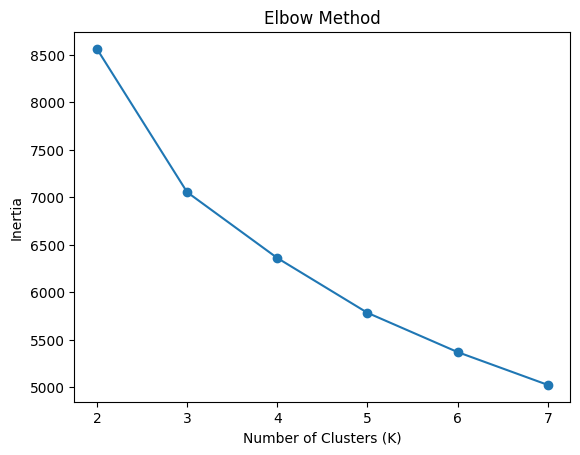

Silhouette scores: {2: np.float64(0.4811241347524294), 3: np.float64(0.3970290774895379), 4: np.float64(0.36830543242775043), 5: np.float64(0.34062159504770945), 6: np.float64(0.34227709867700146), 7: np.float64(0.26872868005477607)}
Best number of clusters: 2

Customer Segment Summary:
                    Income  MntWines  MntFruits  MntMeatProducts  \
Customer_Segment                                                   
0                 41244.22    145.50       7.42            48.00   
1                 73453.89    610.02      62.77           396.75   

                  MntFishProducts  MntSweetProducts  MntGoldProds  
Customer_Segment                                                   
0                           10.51              7.35         25.19  
1                           89.71             65.16         80.40  


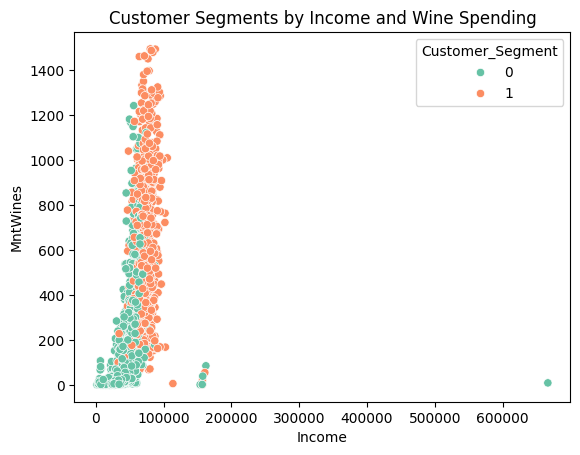


Files created successfully:
customer_segments.csv
segment_summary.csv


In [9]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Load the dataset
url = "https://raw.githubusercontent.com/andhikaw789/Customer-Personality-Analysis/main/marketing_campaign.csv"
df = pd.read_csv(url, sep="\t")

print("Dataset loaded successfully")
print(df.head())

# 2. Select customer features
features = [
    "Income",
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

# 3. Clean the data
data = df[features].copy()
data = data.fillna(data.median())
data = data.clip(
    lower=data.quantile(0.01),
    upper=data.quantile(0.99),
    axis=1
)

# 4. Standardize features
scaler = StandardScaler()
X = scaler.fit_transform(data)

# 5. Find a suitable number of clusters
inertias = []
scores = []
k_values = range(2, 8)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X)

    inertias.append(model.inertia_)
    scores.append(silhouette_score(X, labels))

plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

print("Silhouette scores:", dict(zip(k_values, scores)))

# 6. Train the final clustering model
best_k = list(k_values)[scores.index(max(scores))]
print("Best number of clusters:", best_k)

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

df["Customer_Segment"] = kmeans.fit_predict(X)

# 7. Analyze each customer segment
summary = df.groupby("Customer_Segment")[features].mean().round(2)

print("\nCustomer Segment Summary:")
print(summary)

# 8. Visualize the segments
sns.scatterplot(
    data=df,
    x="Income",
    y="MntWines",
    hue="Customer_Segment",
    palette="Set2"
)

plt.title("Customer Segments by Income and Wine Spending")
plt.show()

# 9. Save the results
df.to_csv("customer_segments.csv", index=False)
summary.to_csv("segment_summary.csv")

print("\nFiles created successfully:")
print("customer_segments.csv")
print("segment_summary.csv")


